# Iris Flower Species Classification
### Machine Learning Internship Project

**Objective:** Build and evaluate a supervised machine-learning classifier that predicts an iris flower's species from four measurements: sepal length, sepal width, petal length, and petal width.

**Target classes:** `Iris-setosa`, `Iris-versicolor`, and `Iris-virginica`.

**Workflow:** data loading → data inspection → exploratory data analysis → preprocessing → model comparison → test-set evaluation → prediction example → model export.

## 1. Project Overview

The Iris dataset contains 150 observations, with 50 samples for each of three species. Each observation has four numerical measurements and one target label (`Species`).

This project uses a stratified 80/20 train-test split. Several classification algorithms are compared using 10-fold stratified cross-validation on the training data. The selected model is then evaluated once on the held-out test set.

**Important:** The test set is kept separate from model selection so the final evaluation is more representative of performance on unseen data.

## 2. Import Libraries

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 3. Load the Dataset

In [4]:
DATA_PATH = Path("data") / "Iris.csv"

if not DATA_PATH.exists():
    # Also support running the notebook from a folder containing Iris.csv directly.
    DATA_PATH = Path("Iris.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Iris.csv was not found. Put the Kaggle Iris.csv file in the 'data' folder "
        "or next to this notebook."
    )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

if "Id" in df.columns:
    df = df.drop(columns=["Id"])

required_columns = [
    "SepalLengthCm", "SepalWidthCm",
    "PetalLengthCm", "PetalWidthCm", "Species"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

df = df[required_columns].copy()
df["Species"] = df["Species"].astype(str).str.strip()

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
display(df.head())

Dataset loaded successfully.
Rows: 150 | Columns: 5


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 4. Understand and Check the Data

We inspect data types, summary statistics, missing values, duplicate rows, and the number of observations in each species.

In [5]:
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nDuplicate rows:", int(df.duplicated().sum()))

print("\nSpecies distribution:")
display(df["Species"].value_counts().to_frame("Count"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Summary statistics:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing values per column:


,Missing values
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0



Duplicate rows: 3

Species distribution:


,Count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


### Data quality decisions

- The four input measurements should be numeric.
- `Species` is the target label.
- `Id`, when present, is removed because it does not describe a flower.
- Missing values are checked explicitly. The supplied Iris dataset is expected to have no missing values; if a different file contains missing values, resolve them before training rather than silently ignoring them.
- Duplicate rows are reported for transparency; they are not automatically deleted.

## 5. Exploratory Data Analysis (EDA)

The plots help compare the measurements across the three species and inspect relationships between features.

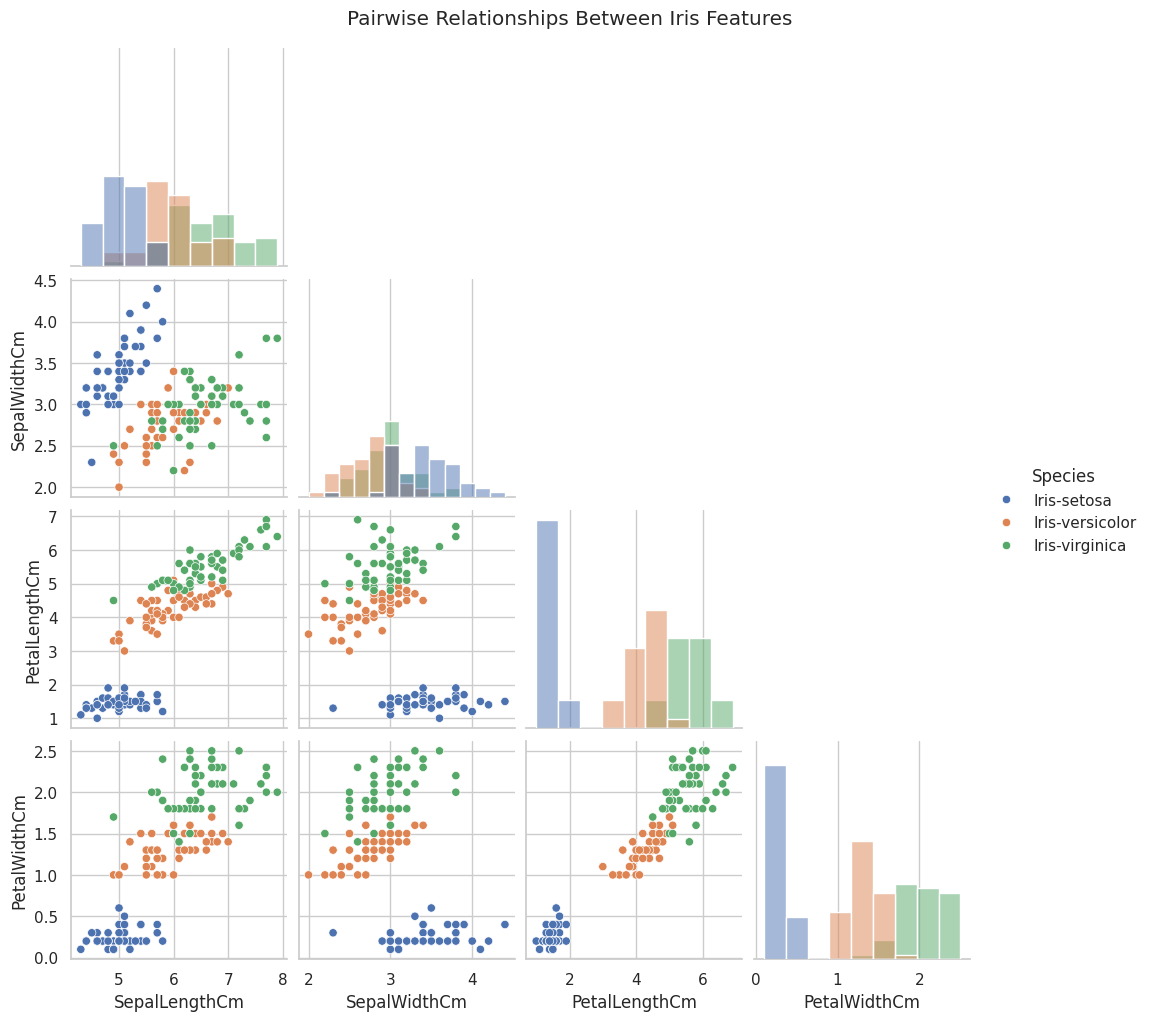

In [6]:
feature_columns = [
    "SepalLengthCm", "SepalWidthCm",
    "PetalLengthCm", "PetalWidthCm"
]

sns.pairplot(df, vars=feature_columns, hue="Species", diag_kind="hist", corner=True)
plt.suptitle("Pairwise Relationships Between Iris Features", y=1.02)
plt.show()

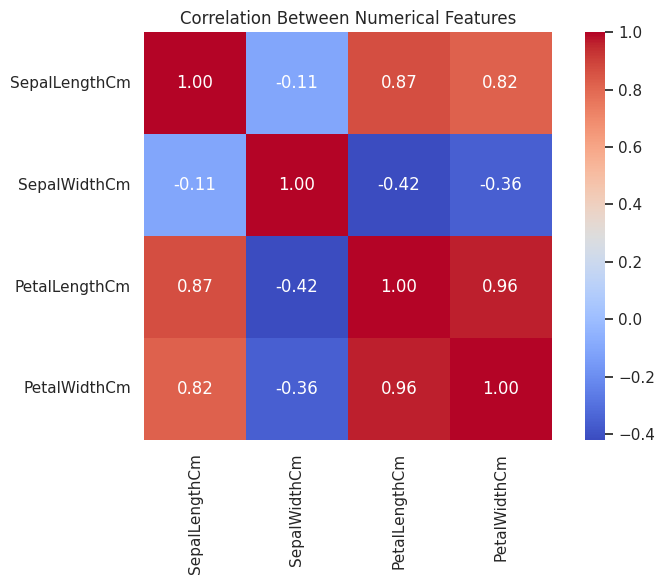

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[feature_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

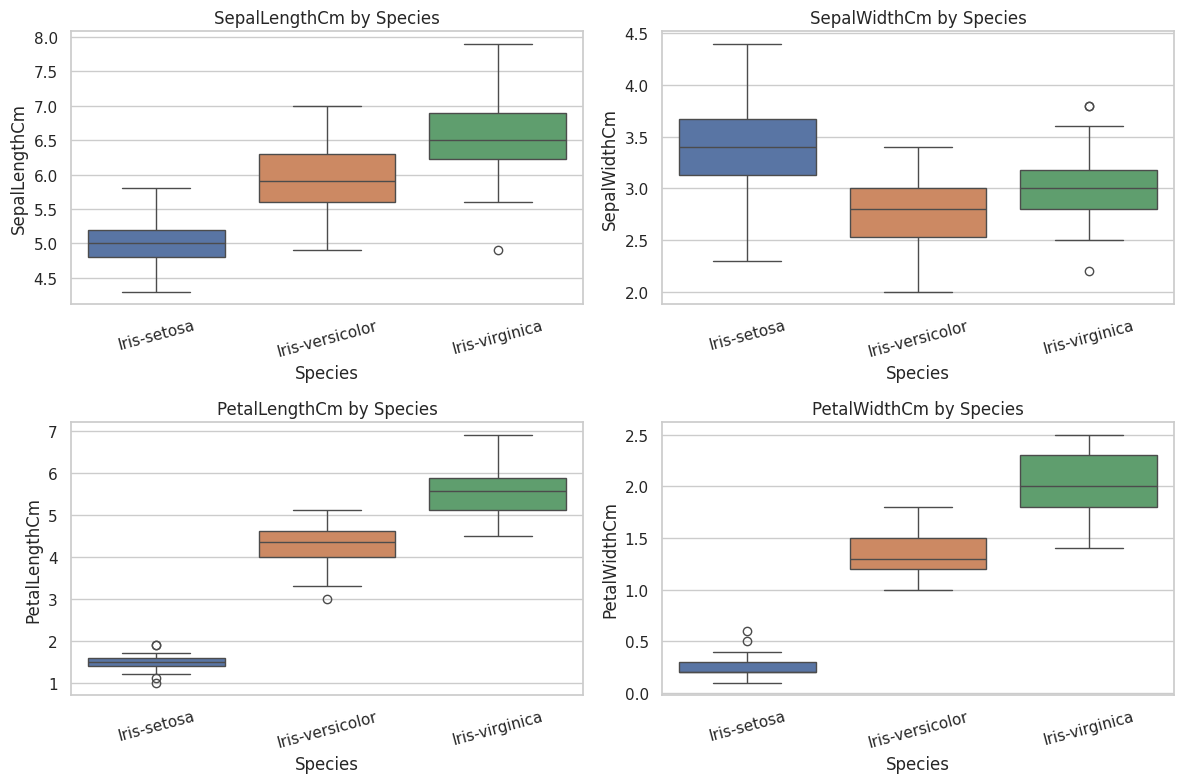

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, feature_columns):
    sns.boxplot(data=df, x="Species", y=feature, hue="Species", legend=False, ax=ax)
    ax.set_title(f"{feature} by Species")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 6. Preprocess the Data

Separate the four features (`X`) from the target (`y`). Split the data before fitting the scaler to prevent information from the test set leaking into preprocessing.

A stratified split preserves the species proportions in both sets. Scaling is placed inside each model's `Pipeline`, so during cross-validation the scaler is fitted only on that fold's training portion.

In [9]:
X = df[feature_columns].copy()
y = df["Species"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")
print("\nTraining class distribution:")
display(y_train.value_counts().sort_index().to_frame("Count"))

Training samples: 120
Testing samples:  30

Training class distribution:


,Count
Species,
Iris-setosa,40
Iris-versicolor,40
Iris-virginica,40


## 7. Train and Compare Classification Models

We compare six commonly used classification algorithms. Standardization is included in each pipeline; it is particularly useful for distance- and margin-based algorithms such as KNN, Logistic Regression, and SVM. Tree-based models are also included for comparison.

In [10]:
model_definitions = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

pipelines = {
    name: Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", estimator)
    ])
    for name, estimator in model_definitions.items()
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, pipeline in pipelines.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

performance_df = pd.DataFrame(cv_rows).sort_values(
    "Mean CV Accuracy", ascending=False
).reset_index(drop=True)

display(performance_df.style.format({
    "Mean CV Accuracy": "{:.4f}",
    "CV Standard Deviation": "{:.4f}"
}))

,Model,Mean CV Accuracy,CV Standard Deviation
0,Support Vector Machine,0.9667,0.0408
1,K-Nearest Neighbors,0.9583,0.0559
2,Logistic Regression,0.9583,0.0417
3,Decision Tree,0.9500,0.0408
4,Random Forest,0.9500,0.0553
5,Gradient Boosting,0.9417,0.0534


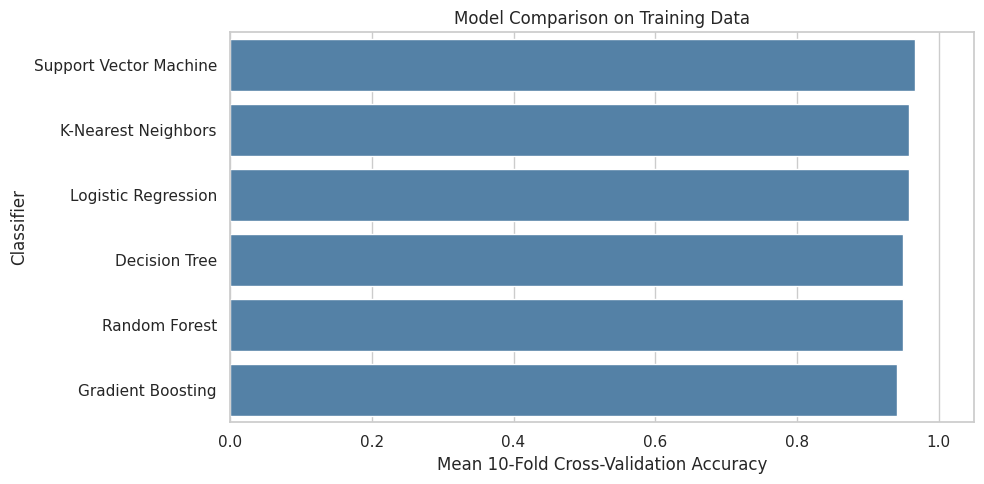

In [11]:
plt.figure(figsize=(10, 5))
sns.barplot(data=performance_df, x="Mean CV Accuracy", y="Model", color="steelblue")
plt.xlim(0, 1.05)
plt.xlabel("Mean 10-Fold Cross-Validation Accuracy")
plt.ylabel("Classifier")
plt.title("Model Comparison on Training Data")
plt.tight_layout()
plt.show()

## 8. Select the Best Model and Evaluate on the Test Set

The model with the highest mean cross-validation accuracy is selected. It is then fitted on the full training set and evaluated on the held-out test set. In the event of a tie, the first model in the sorted comparison is selected.

In [12]:
best_model_name = performance_df.loc[0, "Model"]
best_model = pipelines[best_model_name]
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print("Selected model:", best_model_name)
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Selected model: Support Vector Machine
Test accuracy: 0.9667 (96.67%)

Classification report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



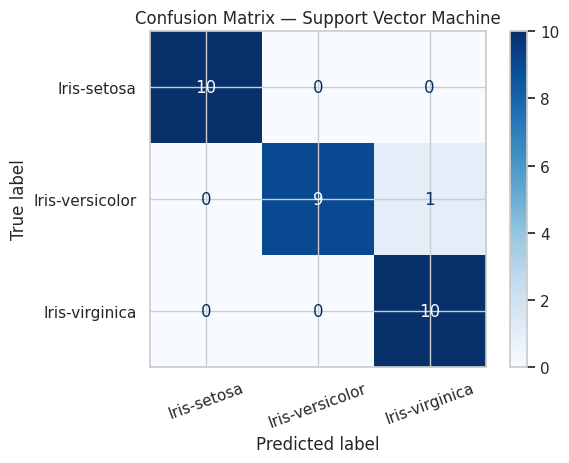

In [13]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d", xticks_rotation=20)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

### How to interpret the metrics

- **Accuracy:** proportion of all test samples classified correctly.
- **Precision:** among samples predicted as a species, the proportion that truly belong to that species.
- **Recall:** among samples that truly belong to a species, the proportion correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** shows correct predictions on the diagonal and misclassifications off the diagonal.

The numerical results shown by this notebook are generated when the notebook is run; use those actual results in any written report.

## 9. Feature Importance (Random Forest Analysis)

Random Forest provides a model-specific estimate of feature importance. This is a separate explanatory analysis and does not replace the selected model's test evaluation.

,Feature,Importance
2,PetalLengthCm,0.453793
3,PetalWidthCm,0.412449
0,SepalLengthCm,0.115873
1,SepalWidthCm,0.017885


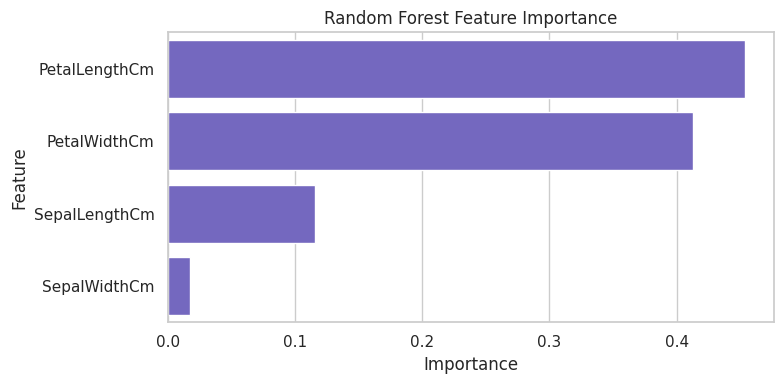

In [14]:
rf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
])
rf_pipeline.fit(X_train, y_train)
rf_importances = rf_pipeline.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_importances
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=importance_df, x="Importance", y="Feature", color="slateblue")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## 10. Predict a New Flower Sample

Enter the four measurements in centimetres. The trained pipeline applies the same scaling operation used during training and returns the predicted species.

In [15]:
sample = pd.DataFrame([{
    "SepalLengthCm": 6.1,
    "SepalWidthCm": 3.0,
    "PetalLengthCm": 4.9,
    "PetalWidthCm": 1.8
}])

predicted_species = best_model.predict(sample)[0]
print("Input measurements:")
display(sample)
print("Predicted species:", predicted_species)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample)[0]
    probability_df = pd.DataFrame({
        "Species": best_model.classes_,
        "Predicted probability": probabilities
    }).sort_values("Predicted probability", ascending=False)
    display(probability_df.style.format({"Predicted probability": "{:.2%}"}))

Input measurements:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,6.1,3.0,4.9,1.8


Predicted species: Iris-virginica


,Species,Predicted probability
2,Iris-virginica,69.52%
1,Iris-versicolor,29.32%
0,Iris-setosa,1.16%


## 11. Save the Trained Model

The complete fitted pipeline is saved with `joblib`. Because the scaler is part of the pipeline, future predictions automatically use the correct preprocessing. Only load model files you trust.

In [16]:
MODEL_PATH = Path("iris_classifier.joblib")
joblib.dump(best_model, MODEL_PATH)
print(f"Saved trained model to: {MODEL_PATH.resolve()}")

Saved trained model to: /content/iris_classifier.joblib


## 12. Conclusion

This Task demonstrates a complete supervised-learning workflow for Iris species classification: inspecting the dataset, visualizing feature relationships, splitting and preprocessing the data, comparing classification algorithms with stratified cross-validation, and evaluating the selected model on unseen test samples.

The final reported accuracy must be taken from the test evaluation cell after running this notebook. The confusion matrix and classification report provide additional detail beyond a single accuracy value.
